## Analyze results low-quality mapping (batch variable dataset, kl1, cellxgene counts)

In [1]:
import scanpy as sc
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors

sys.path.append("../../../src/")
sys.path.append("../../utils/HLCA")
import mapqc
import data_cleanup

In [2]:
%load_ext lab_black
%load_ext autoreload
%autoreload 2

params

In [3]:
study = "Sheppard_2020"
batch_variable = "dataset"
testrun = False
use_old_counts = False
kl = 1.0
mapqc_k = 500
incl_SCD = False

paths:

In [4]:
if testrun:
    suffix = "_test"
    suffix_2 = ""
elif incl_SCD:
    suffix = "_incl_SCD"
else:
    suffix = ""
if use_old_counts == True:
    suffix_2 = "original_counts_"
else:
    suffix_2 = "cellxgene_counts_"

path_emb = f"/lustre/groups/ml01/workspace/lisa.sikkema/mapqc/data/HLCA/HLCA_and_{study}_{suffix_2}batch_{batch_variable}_kl{kl}_latent{suffix}.h5ad"
path_counts = f"/lustre/groups/ml01/workspace/lisa.sikkema/mapqc/data/HLCA/HLCA_and_{study}_counts{suffix}.h5ad"
path_mapqc_results_dir = f"/lustre/groups/ml01/code/lisa.sikkema/mapqc/results/HLCA/{study}/{suffix_2}batch_{batch_variable}_kl{kl}{suffix}/mapqc"
path_figure_dir = (
    "/lustre/groups/ml01/code/lisa.sikkema/mapqc_figures/sheppard_poor_mapping/"
)
path_table_dir = (
    "/lustre/groups/ml01/code/lisa.sikkema/mapqc_tables/sheppard_poor_mapping/"
)

load relevant files:

In [5]:
path_counts

'/lustre/groups/ml01/workspace/lisa.sikkema/mapqc/data/HLCA/HLCA_and_Sheppard_2020_counts.h5ad'

In [6]:
path_emb

'/lustre/groups/ml01/workspace/lisa.sikkema/mapqc/data/HLCA/HLCA_and_Sheppard_2020_cellxgene_counts_batch_dataset_kl1.0_latent.h5ad'

In [7]:
adata_emb = sc.read_h5ad(path_emb)
adata_counts = sc.read_h5ad(path_counts)
adata = data_cleanup.add_mapping_info_to_counts_adata(adata_counts, adata_emb)

set gene symbols as adata.var row names (instead of IDs):

In [8]:
adata.var["ensembl_id"] = adata.var.index
adata.var.index = [
    fn if not pd.isnull(fn) else gid
    for fn, gid in zip(adata.var.feature_name, adata.var.ensembl_id)
]

In [9]:
results_healthy = mapqc.load(
    os.path.join(path_mapqc_results_dir, f"control_edistance_k{mapqc_k}.pkl")
)
results_disease = mapqc.load(
    os.path.join(path_mapqc_results_dir, f"case_edistance_k{mapqc_k}.pkl")
)

In [10]:
path_mapqc_results_dir

'/lustre/groups/ml01/code/lisa.sikkema/mapqc/results/HLCA/Sheppard_2020/cellxgene_counts_batch_dataset_kl1.0/mapqc'

In [11]:
results_healthy.result_stats

{'n_nhoods': 2450,
 'k': 500,
 'max_k': 5000,
 'perc_of_nhoods_passed_filter': 86,
 'n_samples_total': 6,
 'n_samples_with_results': 6,
 'n_samples_not_mixing_with_ref': 3,
 'perc_samples_not_mixing_with_ref': 50,
 'perc_cells_sampled': 99.58,
 'perc_cells_with_results': 98.76,
 'perc_non_mixing_cells': 28.44}

In [12]:
results_disease.result_stats

{'n_nhoods': 2475,
 'k': 500,
 'max_k': 5000,
 'perc_of_nhoods_passed_filter': 71,
 'n_samples_total': 5,
 'n_samples_with_results': 5,
 'n_samples_not_mixing_with_ref': 2,
 'perc_samples_not_mixing_with_ref': 40,
 'perc_cells_sampled': 99.92,
 'perc_cells_with_results': 99.68,
 'perc_non_mixing_cells': 49.87}

correct annotation hierarchy mistake in HLCA: pericytes are said to be part of the fibroblast supergroup, when they are actually a separate cell type

In [13]:
for lev in [2, 3]:
    for ann_colname in [f"ann_level_{lev}", f"ann_level_{lev}_pred"]:
        adata.obs[ann_colname] = adata.obs[ann_colname].tolist()
        results_healthy.adata.obs[ann_colname] = results_healthy.adata.obs[
            ann_colname
        ].tolist()
        results_disease.adata.obs[ann_colname] = results_disease.adata.obs[
            ann_colname
        ].tolist()
        if "_pred" in ann_colname:
            ref_col = "ann_level_5_pred"
        else:
            ref_col = "ann_level_5"
        adata.obs.loc[
            adata.obs[ref_col] == "Pericytes",
            ann_colname,
        ] = "Pericytes"
        results_healthy.adata.obs.loc[
            results_healthy.adata.obs[ref_col] == "Pericytes",
            ann_colname,
        ] = "Pericytes"
        results_disease.adata.obs.loc[
            results_disease.adata.obs[ref_col] == "Pericytes",
            ann_colname,
        ] = "Pericytes"

copy results to main adata:

In [14]:
for stat in [
    "mapqc_score",
    "mapqc_score>2",
]:
    adata.obs[stat] = np.nan
    healthy_idc = [
        idx for idx in adata.obs.index if idx in results_healthy.adata.obs.index
    ]
    adata.obs.loc[healthy_idc, stat] = results_healthy.adata.obs.loc[healthy_idc, stat]
    disease_idc = [
        idx for idx in adata.obs.index if idx in results_disease.adata.obs.index
    ]
    adata.obs.loc[disease_idc, stat] = results_disease.adata.obs.loc[disease_idc, stat]

## Plots:

In [15]:
sc.set_figure_params(figsize=(7, 7))
s = 0.5

In [16]:
FIGURES = dict()
TABLES = dict()

UMAP colored by reference, query control, query case

In [17]:
# create variable splitting data in ref control, query control
adata.obs["r_or_q_ctr_or_case"] = [
    f"{r_q} {stat}" for r_q, stat in zip(adata.obs.r_or_q, adata.obs.status)
]
# clean up:
cleaning_dict = {
    "r control": "Reference (controls)",
    "q control": "Query controls",
    "q IPF": "Query IPF",
}
adata.obs.r_or_q_ctr_or_case = adata.obs.r_or_q_ctr_or_case.map(cleaning_dict)
results_healthy.adata.obs["r_or_q_ctr_or_case"] = adata.obs.loc[
    results_healthy.adata.obs.index, "r_or_q_ctr_or_case"
].copy()
results_disease.adata.obs["r_or_q_ctr_or_case"] = adata.obs.loc[
    results_disease.adata.obs.index, "r_or_q_ctr_or_case"
].copy()
palette_1 = {
    "Reference (controls)": "grey",
    "Query controls": "dodgerblue",
    "Query IPF": "midnightblue",
}
palette_boxplots = {  # need to use a different palette here, as with query dark blue we cannot see individual points on the boxes anymore
    "Reference (controls)": "grey",
    "Query controls": "#75bbfd",
    "Query IPF": matplotlib.colors.to_rgba("#276ab3"),
}

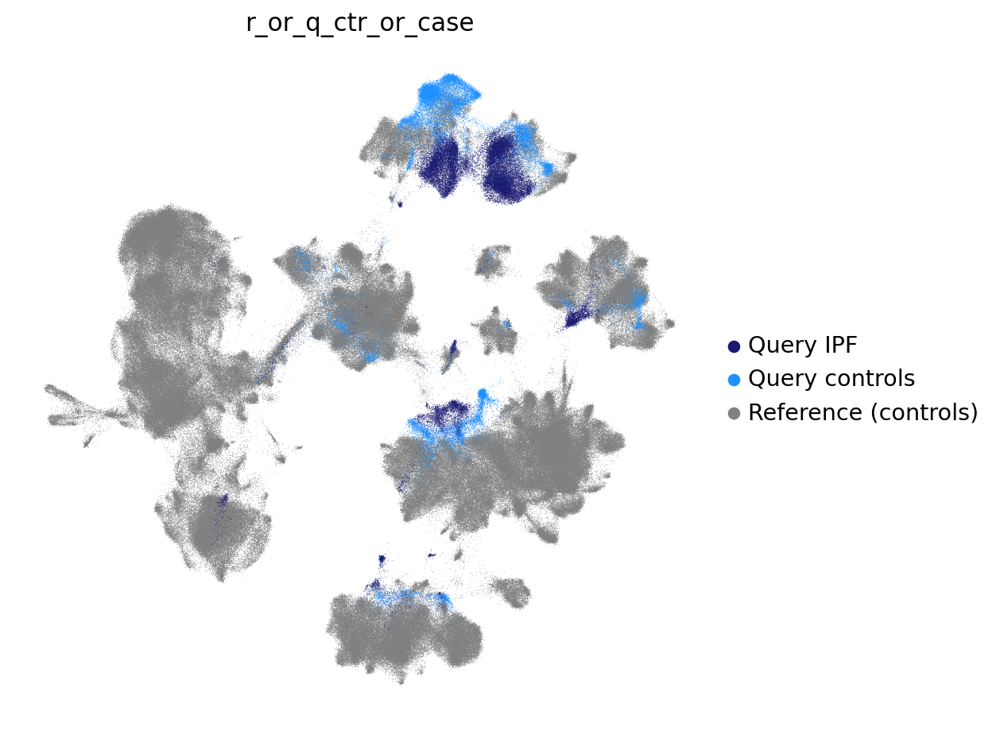

In [18]:
FIGURES["umap_r_or_q_ctr_or_case"] = sc.pl.umap(
    adata,
    color="r_or_q_ctr_or_case",
    frameon=False,
    ncols=1,
    palette=palette_1,
    show=False,
    s=s,
    return_fig=True,
)

UMAP colored by cell type annotation:  

In [19]:
for lev in range(1, 6):
    adata.obs[f"ann_level_{lev}_merged"] = [
        ann if not pd.isnull(ann) else ann_pred
        for ann, ann_pred in zip(
            adata.obs[f"ann_level_{lev}"], adata.obs[f"ann_level_{lev}_pred"]
        )
    ]

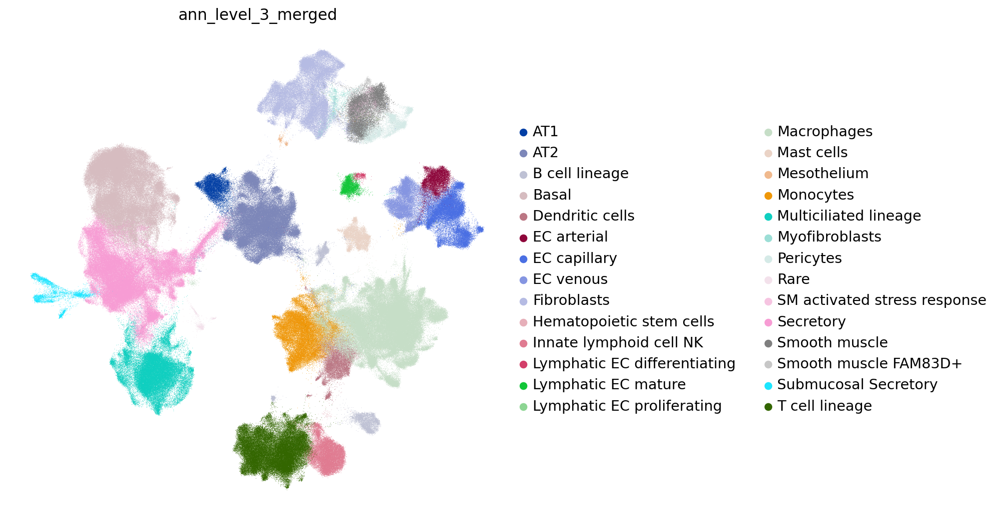

In [20]:
FIGURES["umap_anns"], ax = plt.subplots(figsize=(8, 8))
sc.pl.umap(adata, color="ann_level_3_merged", frameon=False, ax=ax, s=0.7)

UMAP colored by mapqc score controls:

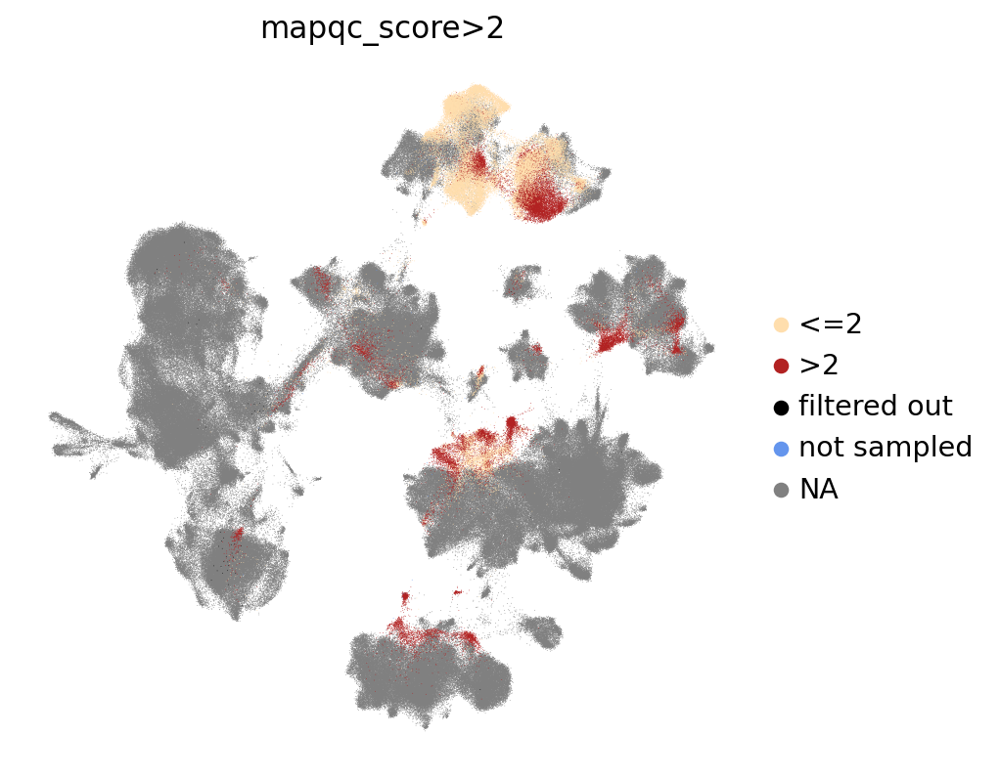

In [21]:
FIGURES["umap_ctr_and_case_mapqc_score_binarized"], ax = plt.subplots(figsize=(6, 6))
sc.pl.umap(
    adata,
    color="mapqc_score>2",
    # return_fig=True,
    size=0.5,
    palette={
        ">2": "firebrick",
        "<=2": "navajowhite",
        "filtered out": "black",
        "not sampled": "cornflowerblue",
    },
    frameon=False,
    na_color="gray",
    ax=ax,
)

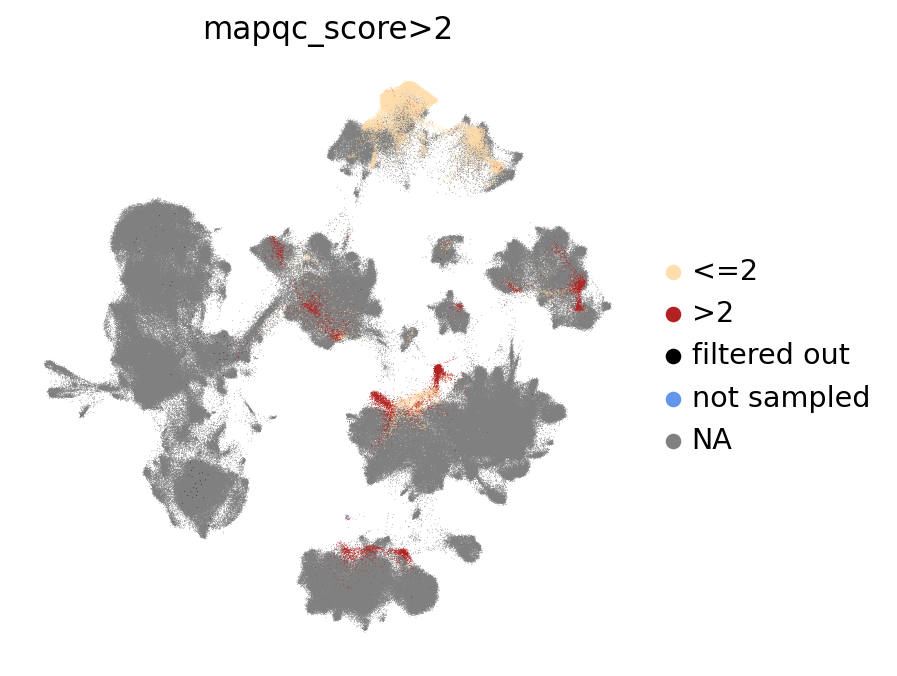

In [22]:
FIGURES["umap_ctr_mapqc_score_binarized"] = mapqc.pl.umap_mapqc_scores(
    results_healthy, color_by="mapqc_score>2", return_fig=True, size=s
)

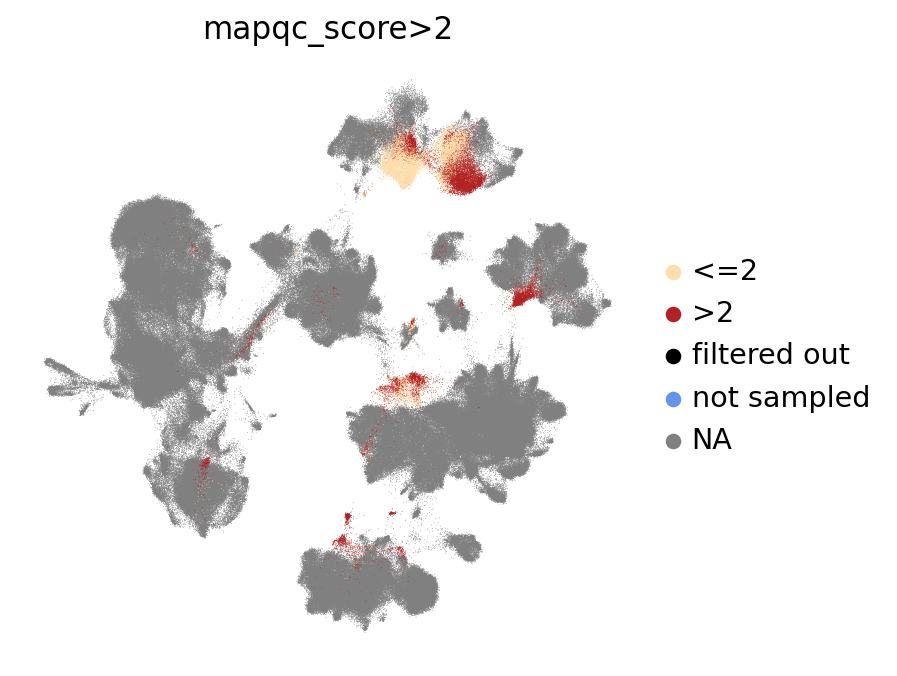

In [23]:
FIGURES["umap_case_mapqc_score_binarized"] = mapqc.pl.umap_mapqc_scores(
    results_disease, color_by="mapqc_score>2", return_fig=True, size=s
)

Boxplot showing mapqc scores in controls per cell type:

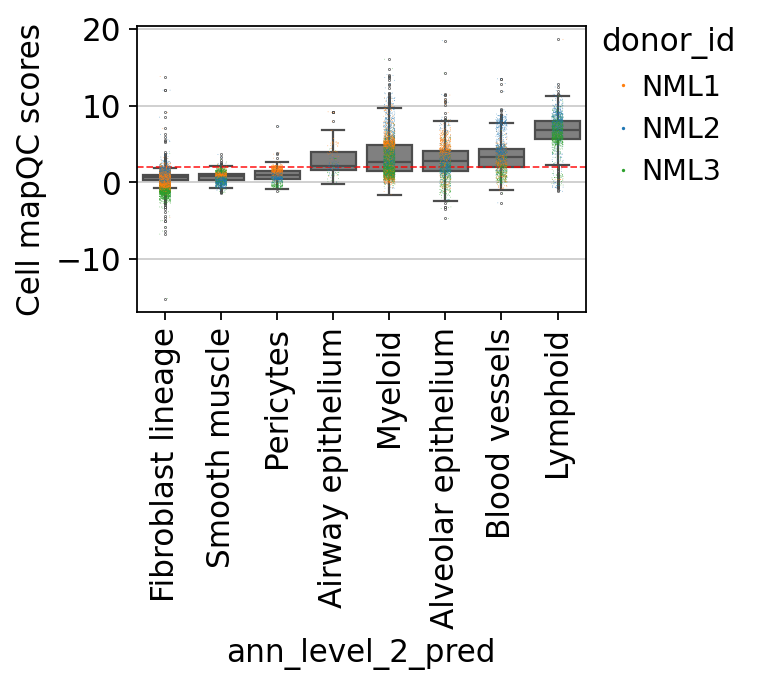

In [24]:
FIGURES["mapqc_per_ct_ctr_only"] = mapqc.pl.boxplot_mapqc_scores_per_category(
    results_healthy,
    box_category="ann_level_2_pred",
    figsize=(5, 4.5),
    point_size=0.3,
    color_category="donor_id",
    return_fig=True,
    min_cells_per_cat=150,
)

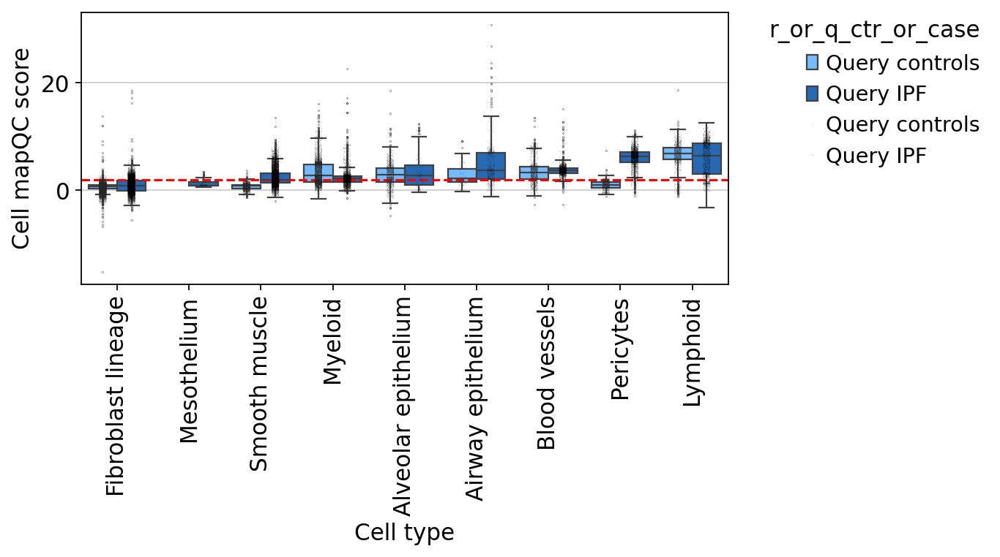

In [25]:
FIGURES[
    "grouped_boxplot_lev2_ann_mapqc_score"
] = mapqc.pl.grouped_boxplot_mapqc_scores_per_category(
    mapqc_results_ctr=results_healthy,
    mapqc_results_case=results_disease,
    box_category="ann_level_2_pred",
    group_category="r_or_q_ctr_or_case",
    palette=palette_boxplots,
    figsize=(9, 5),
    min_cells_per_box=100,
    return_fig=True,
)
plt.xlabel("Cell type")
plt.show()

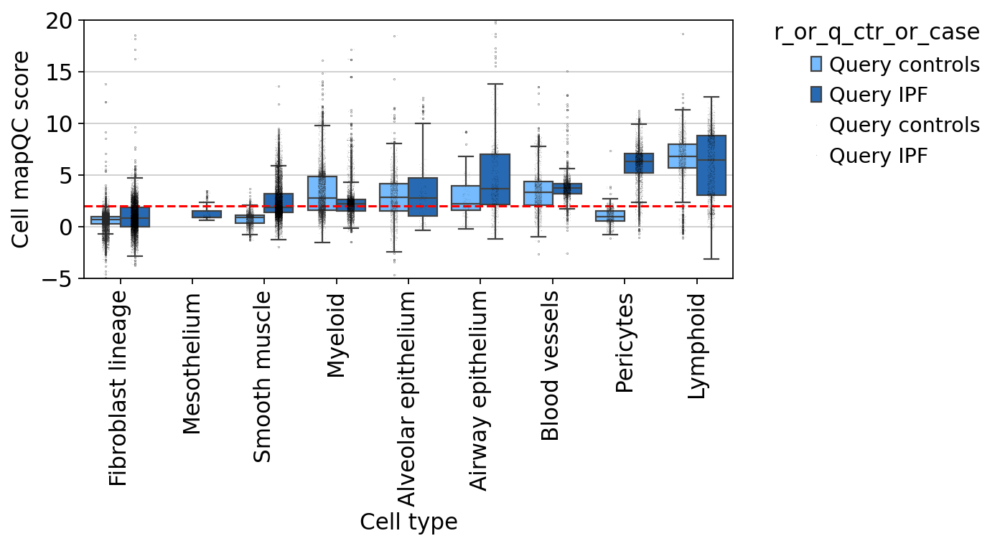

In [26]:
FIGURES[
    "grouped_boxplot_lev2_ann_mapqc_score_cut_axes"
] = mapqc.pl.grouped_boxplot_mapqc_scores_per_category(
    mapqc_results_ctr=results_healthy,
    mapqc_results_case=results_disease,
    box_category="ann_level_2_pred",
    group_category="r_or_q_ctr_or_case",
    palette=palette_boxplots,
    figsize=(9, 5),
    vmax=20,
    vmin=-5,
    min_cells_per_box=100,
    return_fig=True,
)
plt.xlabel("Cell type")
plt.show()

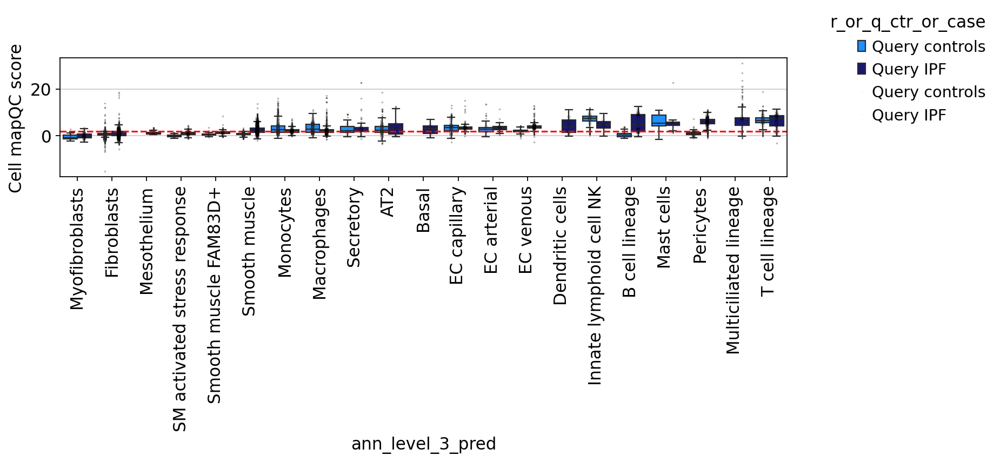

In [27]:
mapqc.pl.grouped_boxplot_mapqc_scores_per_category(
    mapqc_results_ctr=results_healthy,
    mapqc_results_case=results_disease,
    box_category="ann_level_3_pred",
    group_category="r_or_q_ctr_or_case",
    palette=palette_1,
    figsize=(12, 5),
    min_cells_per_box=50,
)

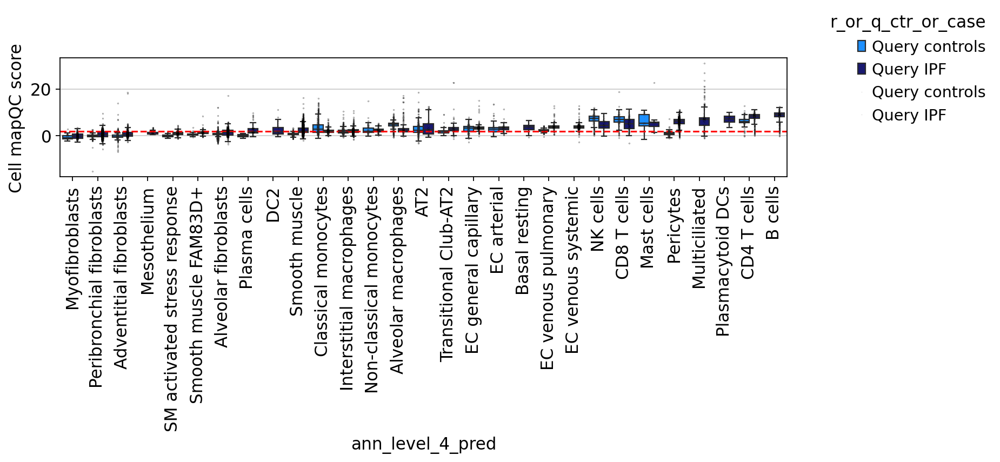

In [28]:
mapqc.pl.grouped_boxplot_mapqc_scores_per_category(
    mapqc_results_ctr=results_healthy,
    mapqc_results_case=results_disease,
    box_category="ann_level_4_pred",
    group_category="r_or_q_ctr_or_case",
    palette=palette_1,
    figsize=(12, 5),
    min_cells_per_box=50,
)

### Analysis endothelial cells:

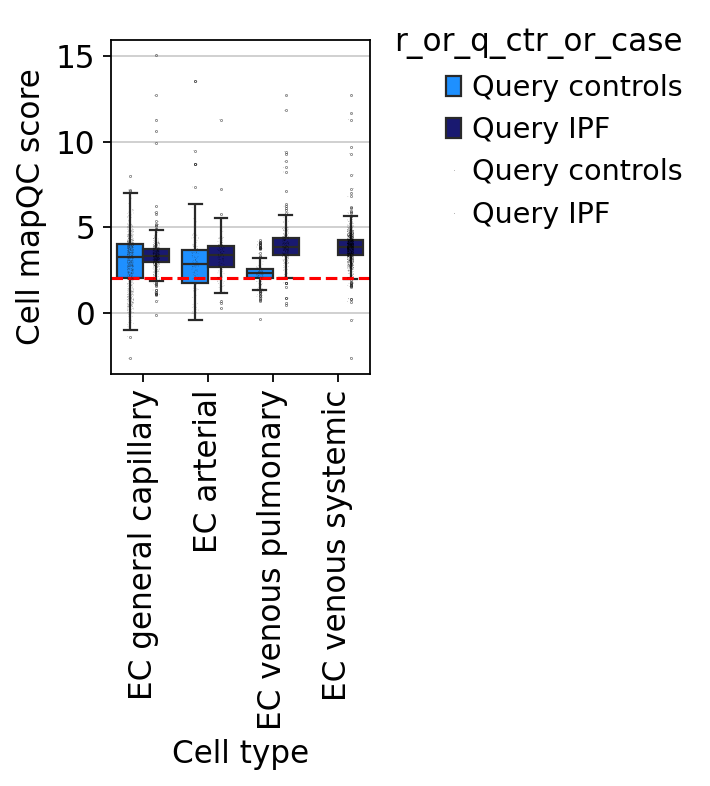

In [29]:
FIGURES[
    "grouped_barplot_end_subtype_mapqc_scores"
] = mapqc.pl.grouped_boxplot_mapqc_scores_per_category(
    mapqc_results_ctr=results_healthy,
    mapqc_results_case=results_disease,
    box_category="ann_level_5_pred",
    group_category="r_or_q_ctr_or_case",
    box_groups_to_include=[
        "EC aerocyte capillary",
        "EC arterial",
        "EC general capillary",
        "EC venous pulmonary",
        "EC venous systemic",
    ],
    figsize=(5, 5),
    palette=palette_1,
    min_cells_per_box=50,
    return_fig=True,
)
plt.xlabel("Cell type")
plt.show()

subset to endothelial cells:

In [30]:
adata_end = adata[adata.obs.ann_level_2_merged == "Blood vessels", :].copy()

re-run knn graph and umap

In [31]:
sc.pp.neighbors(adata_end, n_neighbors=30, use_rep="X_scanvi_emb")
sc.tl.umap(adata_end)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_basic/lib/python3.9/site-packages/umap/distances.py:1063: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit()
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_basic/lib/python3.9/site-packages/umap/distances.py:1071: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit()
/home/icb/lisa.sikkema/miniconda3/envs/m

In [32]:
sc.tl.leiden(adata_end, key_added="leiden_end", resolution=0.3)

/tmp/ipykernel_6806/357645113.py:1: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata_end, key_added="leiden_end", resolution=0.3)


clean up EC annotations:

In [33]:
adata_end.obs["ann_level_5_cleaned"] = adata_end.obs[
    "ann_level_5_cleaned"
] = data_cleanup.clean_up_df_column(
    adata_end.obs, column_name="ann_level_5_merged", min_n_cells_per_cat=50
)
palette_2 = {
    "EC aerocyte capillary": "#377eb8",  # "tab:blue",
    "EC arterial": "#ff7f00",  # "tab:orange",
    "EC general capillary": "#4daf4a",
    "EC venous pulmonary": "#f781bf",
    "EC venous systemic": "#a65628",
    "Other": "#a9a9a9",
}

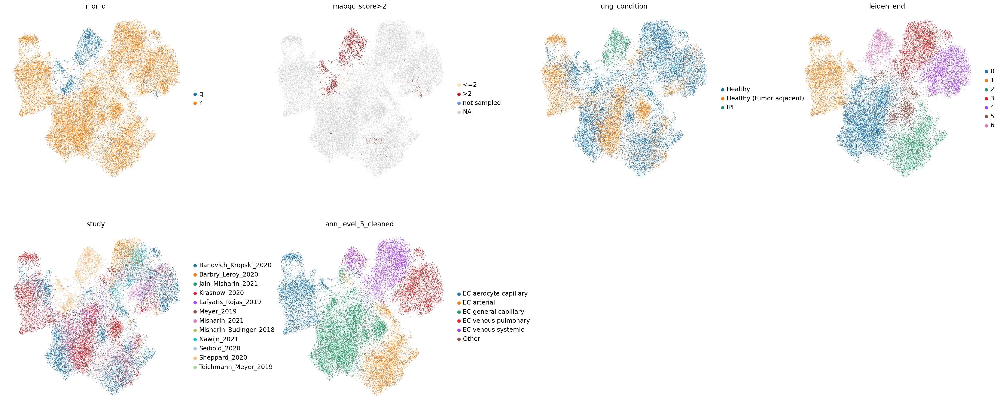

In [34]:
sc.pl.umap(
    adata_end,
    color=[
        "r_or_q",
        "mapqc_score>2",
        "lung_condition",
        "leiden_end",
        "study",
        "ann_level_5_cleaned",
    ],
    wspace=0.3,
    frameon=False,
)

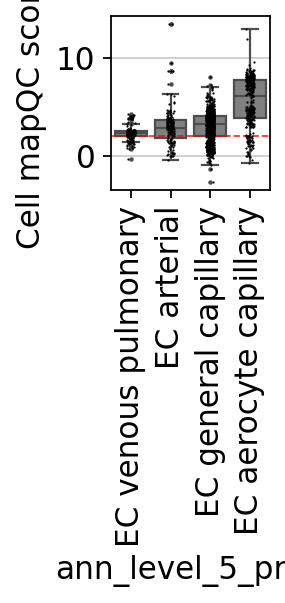

In [35]:
mapqc.pl.boxplot_mapqc_scores_per_category(
    mapqc_results=results_healthy,
    box_category="ann_level_5_pred",
    groups_to_include=[
        "EC aerocyte capillary",
        "EC arterial",
        "EC general capillary",
        "EC venous pulmonary",
        "EC venous systemic",
    ],
    figsize=(2, 4),
    color_high_median_boxes_red=False,
    min_cells_per_cat=50,
)

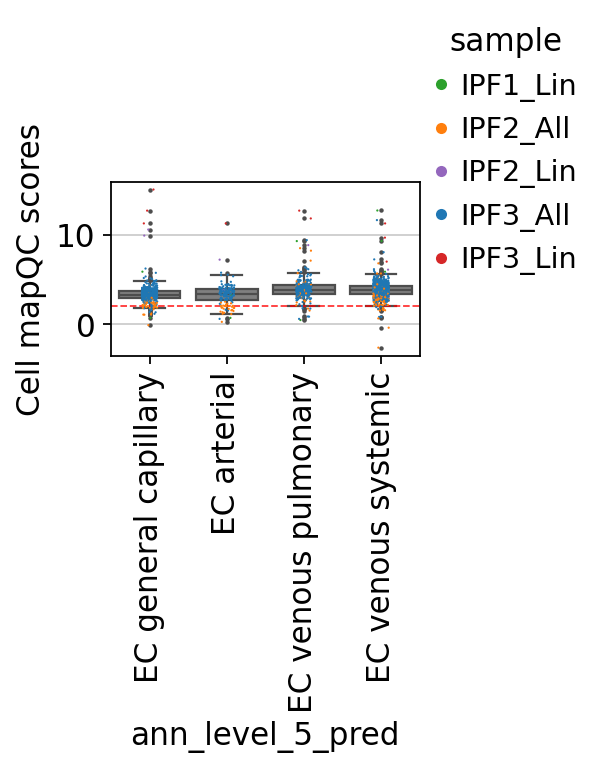

In [36]:
mapqc.pl.boxplot_mapqc_scores_per_category(
    mapqc_results=results_disease,
    box_category="ann_level_5_pred",
    color_category="sample",
    groups_to_include=[
        "EC aerocyte capillary",
        "EC arterial",
        "EC general capillary",
        "EC venous pulmonary",
        "EC venous systemic",
    ],
    figsize=(4, 4),
    min_cells_per_cat=50,
    color_high_median_boxes_red=False,
)

show cluster make-up:

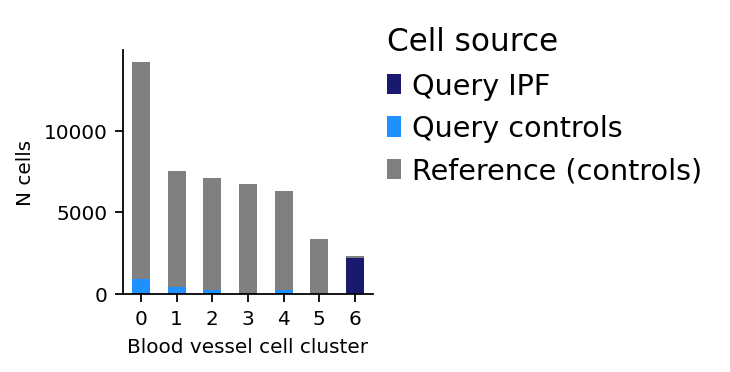

In [37]:
FIGURES["EC_cluster_barplot"], ax = plt.subplots(figsize=(2, 2))
fz = 9
pd.crosstab(adata_end.obs.leiden_end, adata_end.obs.r_or_q_ctr_or_case).plot(
    kind="bar", stacked=True, color=palette_1, ax=ax, fontsize=fz
)
leg = plt.legend(loc=(1.01, 0.4), frameon=False, title="Cell source")
leg._legend_box.align = "left"
ax.spines[["right", "top"]].set_visible(False)
ax.set_ylabel("N cells", fontsize=fz)
ax.set_xlabel("Blood vessel cell cluster", fontsize=fz)
ax.tick_params(axis="x", rotation=0)
plt.grid(False)
plt.show()

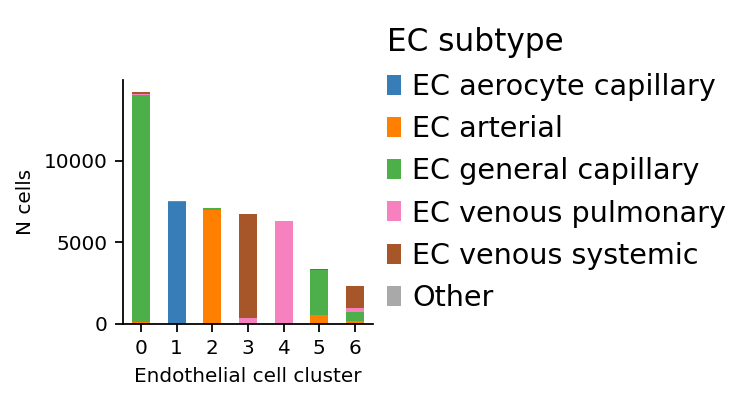

In [38]:
FIGURES["EC_subtype_barplot"], ax = plt.subplots(figsize=(2, 2))
pd.crosstab(adata_end.obs.leiden_end, adata_end.obs.ann_level_5_cleaned).plot(
    kind="bar", stacked=True, ax=ax, color=palette_2, fontsize=fz
)
leg = plt.legend(loc=(1.01, 0), frameon=False, title="EC subtype")
leg._legend_box.align = "left"
ax.spines[["right", "top"]].set_visible(False)
ax.set_ylabel("N cells", fontsize=fz)
ax.set_xlabel("Endothelial cell cluster", fontsize=fz)
ax.tick_params(axis="x", rotation=0)
plt.grid(False)
plt.show()

marker plot:

In [39]:
EC_markers = {
    "EC": ["SPARCL1", "AQP1", "RNASE1"],
    "EC arterial": ["DKK2", "IGFBP3"],
    "EC aerocyte capillary": ["SOSTDC1"],
    "EC general capillary": ["IL7R", "FCN3", "MT1M"],
    "EC venous systemic": ["TPD52L1", "ZNF385D", "OLFM1"],
    "EC venous pulmonary": [
        "CPE",
        "C7_ENSG00000112936",
        "MMRN1",
    ],  # gene with long name is actually C7 but somehow it is named with ensembl id here...
}

In [40]:
adata_end.obs["ct_r_or_q"] = [
    f"{ct} ({r_or_q})"
    for ct, r_or_q in zip(adata_end.obs.ann_level_5_cleaned, adata_end.obs.r_or_q)
]

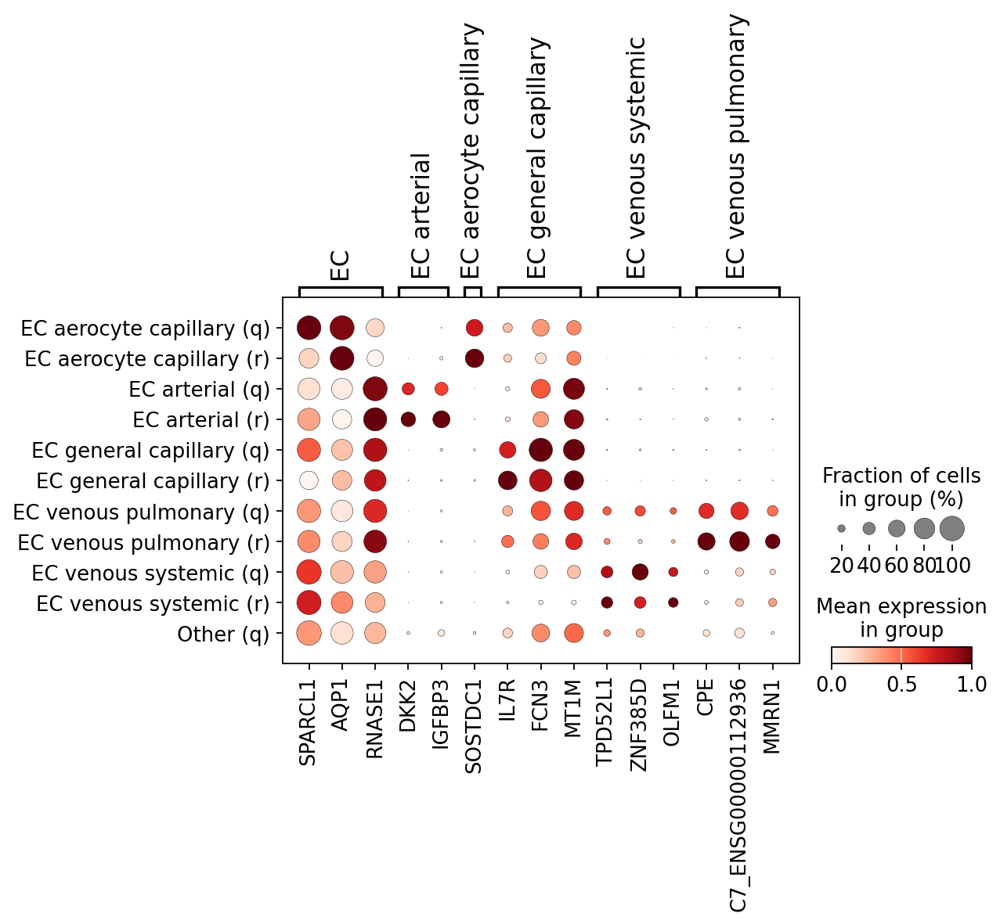

In [41]:
sc.pl.dotplot(
    adata_end, var_names=EC_markers, groupby="ct_r_or_q", standard_scale="var"
)

##### Identify genes associated with low mixing:

In [42]:
sc.tl.rank_genes_groups(adata_end, groupby="leiden_end", reference="rest", groups=["6"])

In [43]:
sc.tl.filter_rank_genes_groups(adata_end)

In [44]:
genes_used_for_mapping = pd.read_csv(
    "../HLCA_reference_model/var_names.csv", index_col=0, header=None
)
id_to_name_mapper = {
    gid: gn for gid, gn in zip(adata.var.ensembl_id, adata.var.feature_name)
}
genes_used_for_mapping["gene_id"] = genes_used_for_mapping.index
genes_used_for_mapping.index = genes_used_for_mapping.gene_id.map(id_to_name_mapper)

In [45]:
end_degs_table = sc.get.rank_genes_groups_df(
    adata_end, key="rank_genes_groups", group="6"
)  # supplementary table
end_degs_filt = sc.get.rank_genes_groups_df(
    adata_end, key="rank_genes_groups_filtered", group="6"
).dropna(how="any")
end_degs_filt["used_during_mapping"] = end_degs_filt.names.isin(
    genes_used_for_mapping.index
)
end_degs_table["used_during_mapping"] = end_degs_table.names.isin(
    genes_used_for_mapping.index
)
end_degs_table["passed_filtering"] = end_degs_table.names.isin(end_degs_filt.names)
TABLES["end_degs"] = end_degs_table

Plot top 10 DEGs that pass standard filtering, and showing only those that were used during mapping. These include, among others, B cell genes ("IGKC","IGHA1","IGLC2"), smooth muscle gene ("MYL9"), stress gene ("FOSB"), EC subtype-specific genes ("NNMT", "ACKR1")

In [46]:
adata_end.obs["leiden_end_r_or_q_ctr_or_case"] = [
    f"{cl} ({status})"
    for cl, status in zip(adata_end.obs.leiden_end, adata_end.obs.r_or_q_ctr_or_case)
]
# set groups with fewer than min_n_cells_per_group to Other:
group_counts = adata_end.obs.leiden_end_r_or_q_ctr_or_case.value_counts()
min_n_cells = 50
other_groups = group_counts[group_counts < 50].index.tolist()
mapping = {
    gr: (gr if gr not in other_groups else "Other")
    for gr in adata_end.obs.leiden_end_r_or_q_ctr_or_case.unique()
}
adata_end.obs.leiden_end_r_or_q_ctr_or_case = (
    adata_end.obs.leiden_end_r_or_q_ctr_or_case.map(mapping)
)

In [47]:
top_filtered_degs = end_degs_filt.names.iloc[:30][
    end_degs_filt.used_during_mapping.iloc[:30]
]
print(f"{len(top_filtered_degs)} genes:")
print(top_filtered_degs)

10 genes:
1       IGKC
5      IGHA1
43      NNMT
49     SPRY1
54     IGLC2
78    PCAT19
82      MYL9
89      FOSB
92    RPS4Y1
93     ACKR1
Name: names, dtype: object


In [49]:
gene_dict = {
    "EC subtype specific": ["NNMT", "ACKR1", "SPRY1"],
    "Ambient B cell": ["IGKC", "IGHA1", "IGLC2"],
    "Amb. smooth muscle": ["MYL9"],
    "Dissociation stress": ["FOSB"],
    "Ribosomal": ["RPS4Y1"],
    "Other": ["PCAT19"],
}

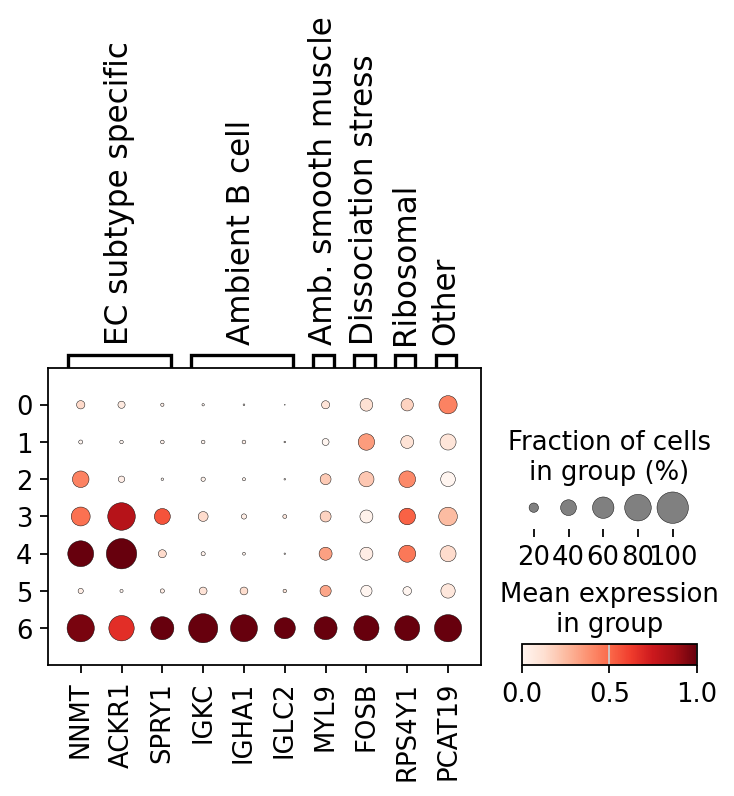

In [50]:
FIGURES["dotplot_end_IPF_cluster_degs"] = sc.pl.dotplot(
    adata_end,
    var_names=gene_dict,
    groupby="leiden_end",
    standard_scale="var",
    return_fig=True,
)
FIGURES["dotplot_end_IPF_cluster_degs"].show()

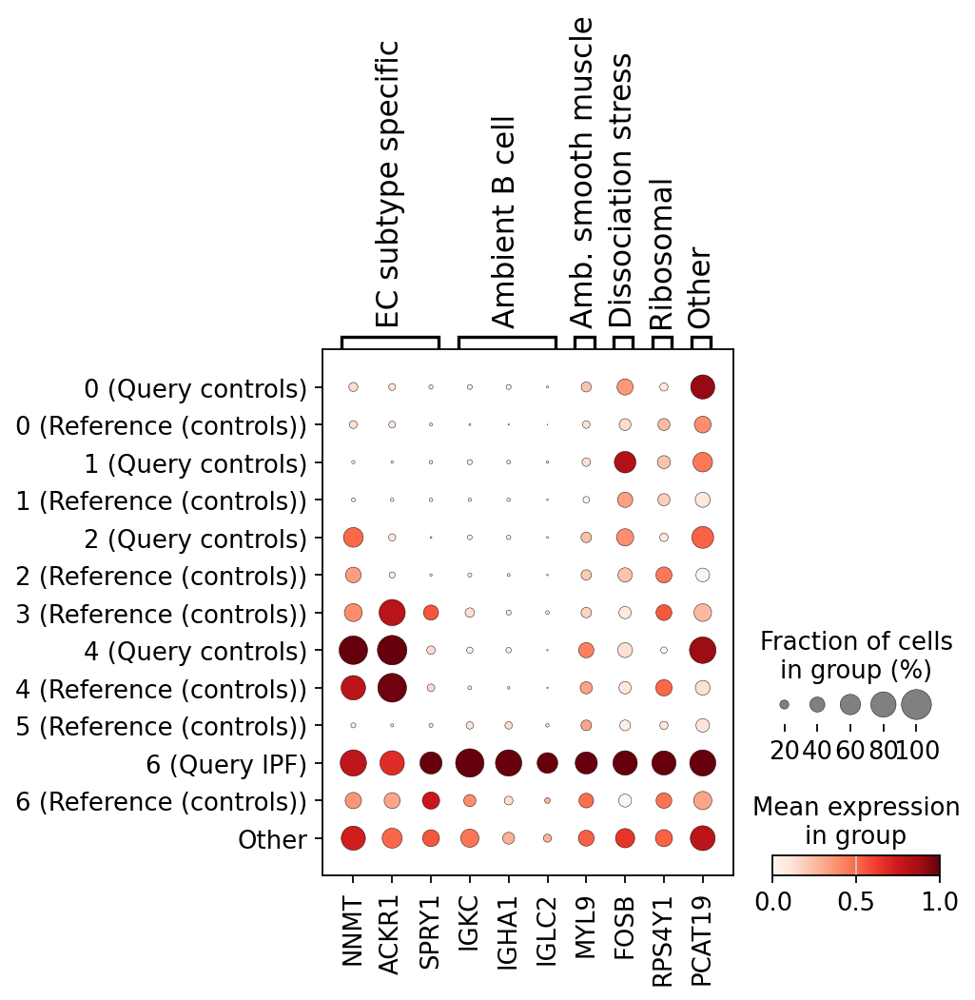

In [51]:
FIGURES["dotplot_end_IPF_cluster_degs_split_by_status"] = sc.pl.dotplot(
    adata_end,
    var_names=gene_dict,
    groupby="leiden_end_r_or_q_ctr_or_case",
    standard_scale="var",
    return_fig=True,
)
FIGURES["dotplot_end_IPF_cluster_degs_split_by_status"].show()

check ambience of gene (note that this data consist of lineage-specific samples (i.e. stroma) and samples with all lineages, and that ambient RNA likely occurred in the "all samples")

In [52]:
adata.obs["ann_level_2_r_or_q_ctr_or_case"] = [
    f"{ann} ({status})"
    for ann, status in zip(adata.obs.ann_level_2_merged, adata.obs.r_or_q_ctr_or_case)
]
adata.obs["ann_level_2_r_or_q_ctr_or_case"] = data_cleanup.clean_up_df_column(
    adata.obs, "ann_level_2_r_or_q_ctr_or_case", min_n_cells_per_cat=200
)

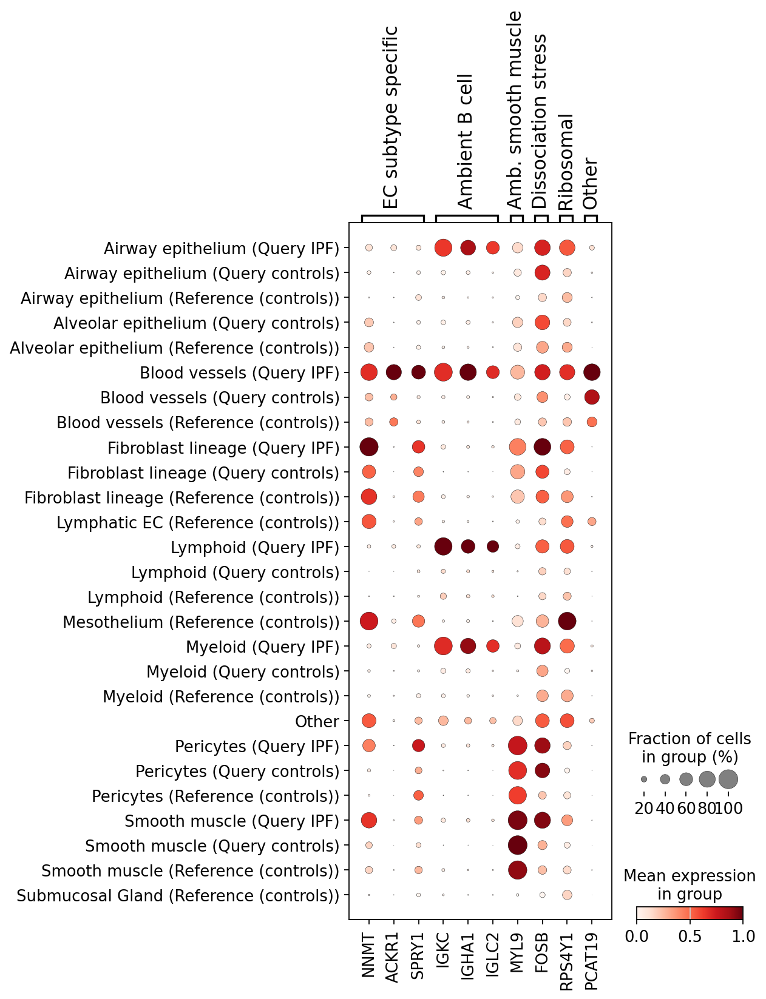

In [53]:
FIGURES["dotplot_all_cells_IPF_cluster_degs_split_by_status"] = sc.pl.dotplot(
    adata,
    var_names=gene_dict,
    groupby="ann_level_2_r_or_q_ctr_or_case",
    standard_scale="var",
    return_fig=True,
)
FIGURES["dotplot_all_cells_IPF_cluster_degs_split_by_status"].show()

## Store figures and tables:

In [57]:
path_figure_dir

'/lustre/groups/ml01/code/lisa.sikkema/mapqc_figures/sheppard_poor_mapping/'

In [54]:
FIGURES

{'umap_r_or_q_ctr_or_case': <Figure size 560x560 with 1 Axes>,
 'umap_anns': <Figure size 640x640 with 1 Axes>,
 'umap_ctr_and_case_mapqc_score_binarized': <Figure size 480x480 with 1 Axes>,
 'umap_ctr_mapqc_score_binarized': <Figure size 400x400 with 1 Axes>,
 'umap_case_mapqc_score_binarized': <Figure size 400x400 with 1 Axes>,
 'mapqc_per_ct_ctr_only': <Figure size 400x360 with 1 Axes>,
 'grouped_boxplot_lev2_ann_mapqc_score': <Figure size 720x400 with 1 Axes>,
 'grouped_boxplot_lev2_ann_mapqc_score_cut_axes': <Figure size 720x400 with 1 Axes>,
 'grouped_barplot_end_subtype_mapqc_scores': <Figure size 400x400 with 1 Axes>,
 'EC_cluster_barplot': <Figure size 160x160 with 1 Axes>,
 'EC_subtype_barplot': <Figure size 160x160 with 1 Axes>,
 'dotplot_end_IPF_cluster_degs': <scanpy.plotting._dotplot.DotPlot at 0x7f8305dc7280>,
 'dotplot_end_IPF_cluster_degs_split_by_status': <scanpy.plotting._dotplot.DotPlot at 0x7f8045fe5dc0>,
 'dotplot_all_cells_IPF_cluster_degs_split_by_status': <scan

In [55]:
for figname, fig in FIGURES.items():
    # if "umap" not in figname:  # TEMP FOR FASTER SAVING, ALREADY HAVE ALL UMAPS
    print("Saving", figname)
    fig.savefig(
        os.path.join(path_figure_dir, f"{figname}.png"),
        bbox_inches="tight",
        dpi=140,
        transparent=True,
    )
    plt.close()

Saving umap_r_or_q_ctr_or_case
Saving umap_anns
Saving umap_ctr_and_case_mapqc_score_binarized
Saving umap_ctr_mapqc_score_binarized
Saving umap_case_mapqc_score_binarized
Saving mapqc_per_ct_ctr_only
Saving grouped_boxplot_lev2_ann_mapqc_score
Saving grouped_boxplot_lev2_ann_mapqc_score_cut_axes
Saving grouped_barplot_end_subtype_mapqc_scores
Saving EC_cluster_barplot
Saving EC_subtype_barplot
Saving dotplot_end_IPF_cluster_degs
Saving dotplot_end_IPF_cluster_degs_split_by_status
Saving dotplot_all_cells_IPF_cluster_degs_split_by_status


In [56]:
TABLES["end_degs"].to_csv(
    os.path.join(path_table_dir, "endothelial_cluster_6_versus_rest.csv"), index=False
)